In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 한글 폰트 설정
plt.rcParams['axes.unicode_minus'] = False

# 최종 통합 데이터 불러오기
df = pd.read_csv('../data/final/시군구_기후복지_통합데이터.csv', encoding='utf-8-sig')

# 데이터 확인
df.head()

,시도,시군구,연도,고령인구,노인_1인가구,경도,위도,관측소_지점,관측소명,관측소_시도,...,여름관측일수,여름부족일수,여름관측_주의,한파일수,관측일수_y,겨울관측일수,겨울부족일수,겨울관측_주의,무더위쉼터_개수,한파쉼터_개수
0,강원특별자치도,강릉시,2021,47318,10813,128.883209,37.709604,105,강릉,강원특별자치도,...,122,0,False,4,365,151,0,False,193,202
1,강원특별자치도,고성군,2021,8236,2006,128.358361,38.401009,90,속초,강원특별자치도,...,122,0,False,7,365,151,0,False,28,28
2,강원특별자치도,동해시,2021,19039,4615,129.045397,37.515759,106,동해,강원특별자치도,...,122,0,False,2,365,151,0,False,157,157
3,강원특별자치도,삼척시,2021,16884,4335,129.173724,37.257882,216,태백,강원특별자치도,...,122,0,False,19,365,151,0,False,63,63
4,강원특별자치도,속초시,2021,16673,4313,128.515038,38.175014,90,속초,강원특별자치도,...,122,0,False,7,365,151,0,False,124,58


In [2]:
# 데이터 크기 확인
print("데이터 크기:", df.shape)

# 컬럼명 확인
print("\n컬럼 목록:")
print(df.columns.tolist())

# 데이터 자료형 및 결측치 확인
df.info()

데이터 크기: (1145, 23)

컬럼 목록:
['시도', '시군구', '연도', '고령인구', '노인_1인가구', '경도', '위도', '관측소_지점', '관측소명', '관측소_시도', '거리_km', '폭염일수', '관측일수_x', '여름관측일수', '여름부족일수', '여름관측_주의', '한파일수', '관측일수_y', '겨울관측일수', '겨울부족일수', '겨울관측_주의', '무더위쉼터_개수', '한파쉼터_개수']
<class 'pandas.DataFrame'>
RangeIndex: 1145 entries, 0 to 1144
Data columns (total 23 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   시도        1145 non-null   str    
 1   시군구       1145 non-null   str    
 2   연도        1145 non-null   int64  
 3   고령인구      1145 non-null   int64  
 4   노인_1인가구   1145 non-null   int64  
 5   경도        1145 non-null   float64
 6   위도        1145 non-null   float64
 7   관측소_지점    1145 non-null   int64  
 8   관측소명      1145 non-null   str    
 9   관측소_시도    1145 non-null   str    
 10  거리_km     1145 non-null   float64
 11  폭염일수      1145 non-null   int64  
 12  관측일수_x    1145 non-null   int64  
 13  여름관측일수    1145 non-null   int64  
 14  여름부족일수    1145 non-null   int64  
 15  

In [3]:
df.describe()

,연도,고령인구,노인_1인가구,경도,위도,관측소_지점,거리_km,폭염일수,관측일수_x,여름관측일수,여름부족일수,한파일수,관측일수_y,겨울관측일수,겨울부족일수,무더위쉼터_개수,한파쉼터_개수
count,1145.000000,1145.000000,1145.000000,1145.000000,1145.000000,1145.000000,1145.000000,1145.000000,1145.000000,1145.000000,1145.000000,1145.000000,1145.000000,1145.000000,1145.000000,1145.000000,1145.000000
mean,2023.000000,42747.893450,9328.131878,127.652208,36.393800,173.868996,11.792598,21.024454,365.076856,121.953712,0.046288,4.628821,365.076856,151.159825,0.040175,273.489083,239.519651
std,1.414832,33767.333669,6784.267434,0.923896,1.084361,63.047811,7.455829,13.924601,0.754495,0.376943,0.376943,6.712063,0.754495,0.516977,0.321372,192.496472,190.862429
min,2021.000000,2390.000000,520.000000,124.673125,33.339058,90.000000,0.144519,0.000000,357.000000,114.000000,0.000000,0.000000,357.000000,147.000000,0.000000,23.000000,19.000000
25%,2022.000000,17077.000000,4371.000000,126.926579,35.402723,114.000000,5.552895,10.000000,365.000000,122.000000,0.000000,0.000000,365.000000,151.000000,0.000000,119.000000,71.000000
50%,2023.000000,32434.000000,7448.000000,127.350476,36.382246,156.000000,10.386506,19.000000,365.000000,122.000000,0.000000,2.000000,365.000000,151.000000,0.000000,229.000000,194.000000
75%,2024.000000,60755.000000,12683.000000,128.464029,37.474948,238.000000,17.059955,28.000000,365.000000,122.000000,0.000000,6.000000,365.000000,151.000000,0.000000,381.000000,351.000000
max,2025.000000,205456.000000,48964.000000,130.860114,38.401009,295.000000,30.556337,62.000000,366.000000,122.000000,8.000000,53.000000,366.000000,152.000000,4.000000,975.000000,876.000000


In [4]:
# 1. 컬럼별 결측치 확인
print("===== 컬럼별 결측치 =====")
print(df.isnull().sum())

# 2. 전체 결측치 개수
print("\n전체 결측치:", df.isnull().sum().sum())

# 3. 완전히 동일한 중복 행 확인
print("\n중복 행 개수:", df.duplicated().sum())

# 4. 시도 + 시군구 + 연도 기준 중복 확인
print(
    "\n지역 및 연도 기준 중복:",
    df.duplicated(subset=['시도', '시군구', '연도']).sum()
)

# 5. 연도별 데이터 개수
print("\n===== 연도별 데이터 개수 =====")
print(df['연도'].value_counts().sort_index())

# 6. 시군구 개수 확인
print("\n전체 시군구 개수:", df['시군구'].nunique())

===== 컬럼별 결측치 =====
시도          0
시군구         0
연도          0
고령인구        0
노인_1인가구     0
경도          0
위도          0
관측소_지점      0
관측소명        0
관측소_시도      0
거리_km       0
폭염일수        0
관측일수_x      0
여름관측일수      0
여름부족일수      0
여름관측_주의     0
한파일수        0
관측일수_y      0
겨울관측일수      0
겨울부족일수      0
겨울관측_주의     0
무더위쉼터_개수    0
한파쉼터_개수     0
dtype: int64

전체 결측치: 0

중복 행 개수: 0

지역 및 연도 기준 중복: 0

===== 연도별 데이터 개수 =====
연도
2021    229
2022    229
2023    229
2024    229
2025    229
Name: count, dtype: int64

전체 시군구 개수: 207


In [5]:
# 시도 + 시군구 조합으로 고유 지역 개수 확인
region_count = df[['시도', '시군구']].drop_duplicates()

print("시도 + 시군구 기준 지역 개수:", len(region_count))

# 시군구 이름이 중복되는 지역 확인
duplicate_regions = (
    region_count[region_count.duplicated('시군구', keep=False)]
    .sort_values('시군구')
)

print("\n===== 시군구 이름이 중복되는 지역 =====")
print(duplicate_regions.to_string(index=False))

# 연도별 고유 지역 개수 확인
print("\n===== 연도별 고유 지역 개수 =====")
print(
    df.groupby('연도')[['시도', '시군구']]
    .apply(lambda x: x.drop_duplicates().shape[0])
)

시도 + 시군구 기준 지역 개수: 229

===== 시군구 이름이 중복되는 지역 =====
       시도 시군구
    부산광역시 강서구
    서울특별시 강서구
  강원특별자치도 고성군
     경상남도 고성군
    부산광역시  남구
    대구광역시  남구
    울산광역시  남구
전남광주통합특별시  남구
    인천광역시  동구
    울산광역시  동구
    부산광역시  동구
전남광주통합특별시  동구
    대구광역시  동구
    대전광역시  동구
    대구광역시  북구
전남광주통합특별시  북구
    울산광역시  북구
    부산광역시  북구
전남광주통합특별시  서구
    대전광역시  서구
    부산광역시  서구
    대구광역시  서구
    인천광역시  서구
    서울특별시  중구
    대구광역시  중구
    울산광역시  중구
    대전광역시  중구
    부산광역시  중구
    인천광역시  중구

===== 연도별 고유 지역 개수 =====
연도
2021    229
2022    229
2023    229
2024    229
2025    229
dtype: int64


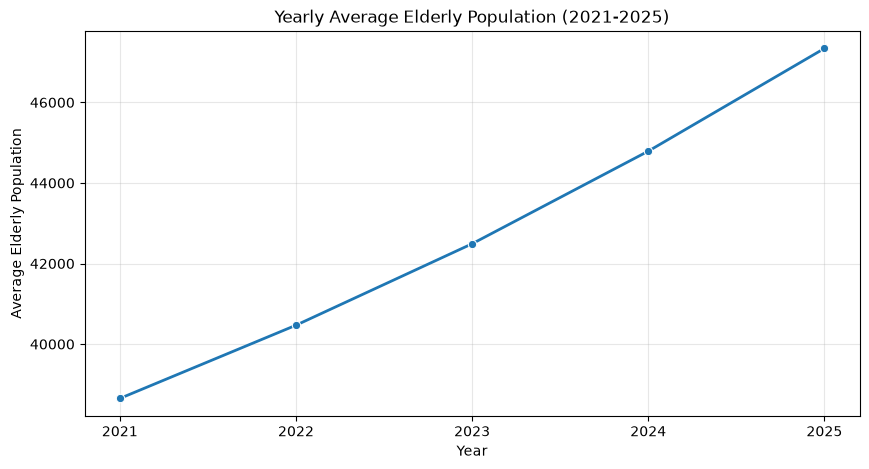

In [6]:
# 연도별 고령인구 평균
elderly_year = df.groupby('연도')['고령인구'].mean()

plt.figure(figsize=(10, 5))

sns.lineplot(
    x=elderly_year.index,
    y=elderly_year.values,
    marker='o',
    linewidth=2
)

plt.title('Yearly Average Elderly Population (2021-2025)')
plt.xlabel('Year')
plt.ylabel('Average Elderly Population')
plt.xticks(range(2021, 2026))
plt.grid(alpha=0.3)

plt.show()

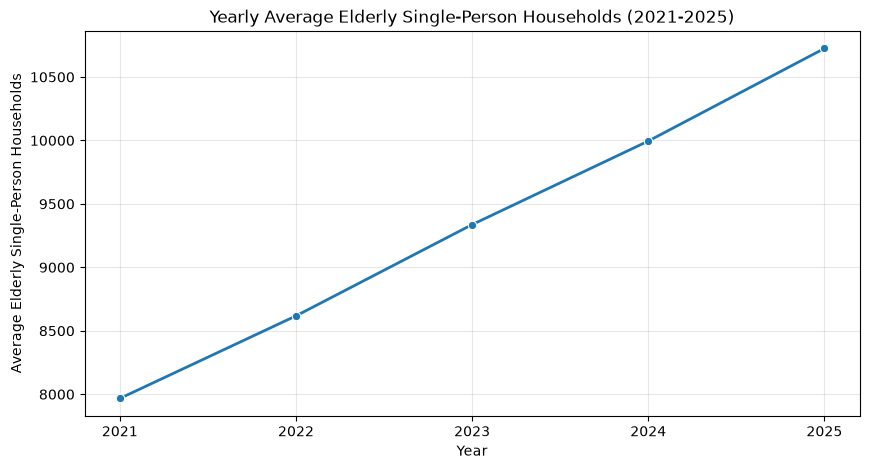

In [7]:
# 연도별 노인 1인가구 평균
single_year = df.groupby('연도')['노인_1인가구'].mean()

plt.figure(figsize=(10, 5))

sns.lineplot(
    x=single_year.index,
    y=single_year.values,
    marker='o',
    linewidth=2
)

plt.title('Yearly Average Elderly Single-Person Households (2021-2025)')
plt.xlabel('Year')
plt.ylabel('Average Elderly Single-Person Households')
plt.xticks(range(2021, 2026))
plt.grid(alpha=0.3)

plt.show()

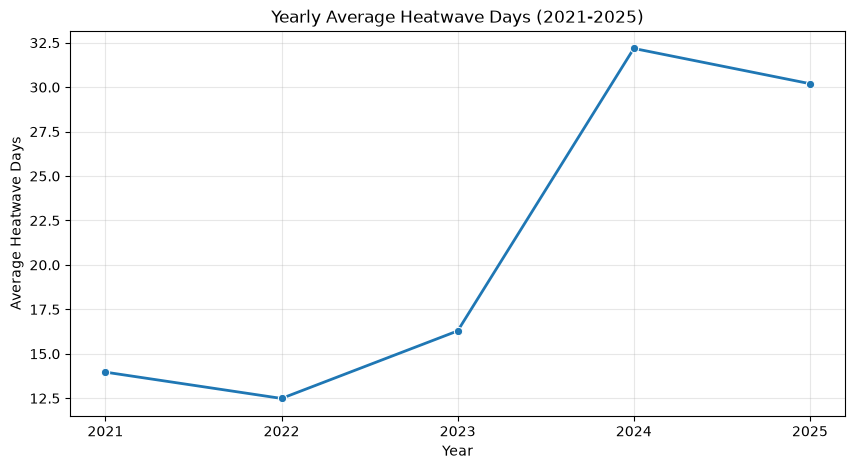

In [8]:
# 연도별 평균 폭염일수
heatwave_year = df.groupby('연도')['폭염일수'].mean()

plt.figure(figsize=(10, 5))

sns.lineplot(
    x=heatwave_year.index,
    y=heatwave_year.values,
    marker='o',
    linewidth=2
)

plt.title('Yearly Average Heatwave Days (2021-2025)')
plt.xlabel('Year')
plt.ylabel('Average Heatwave Days')
plt.xticks(range(2021, 2026))
plt.grid(alpha=0.3)

plt.show()

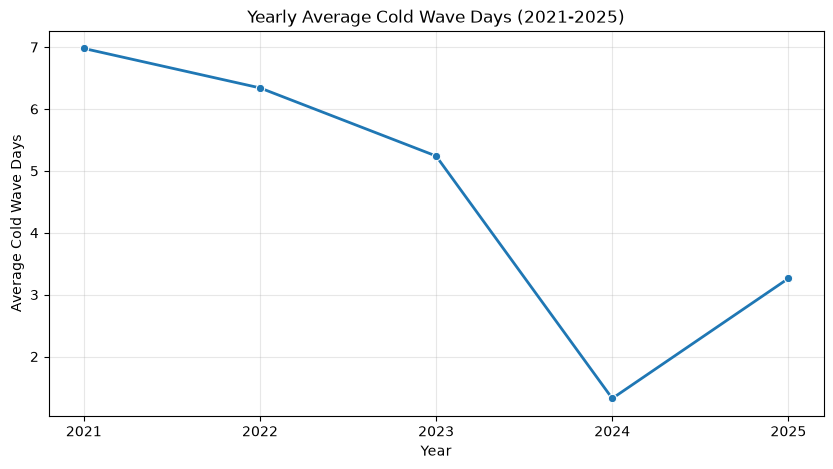

In [9]:
# 연도별 평균 한파일수
coldwave_year = df.groupby('연도')['한파일수'].mean()

plt.figure(figsize=(10, 5))

sns.lineplot(
    x=coldwave_year.index,
    y=coldwave_year.values,
    marker='o',
    linewidth=2
)

plt.title('Yearly Average Cold Wave Days (2021-2025)')
plt.xlabel('Year')
plt.ylabel('Average Cold Wave Days')
plt.xticks(range(2021, 2026))
plt.grid(alpha=0.3)

plt.show()

===== 연도별 평균 쉼터 개수 =====
        무더위쉼터_개수     한파쉼터_개수
연도                          
2021  273.489083  239.519651
2022  273.489083  239.519651
2023  273.489083  239.519651
2024  273.489083  239.519651
2025  273.489083  239.519651


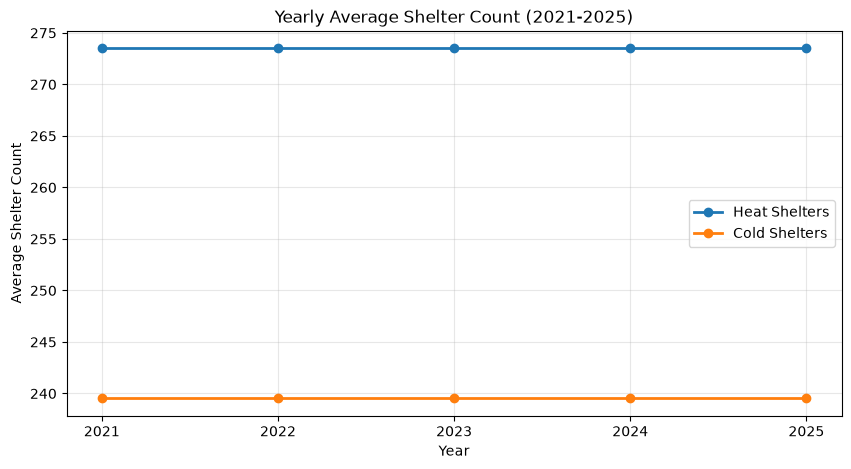

In [10]:
# 연도별 평균 쉼터 개수
shelter_year = df.groupby('연도')[
    ['무더위쉼터_개수', '한파쉼터_개수']
].mean()

print("===== 연도별 평균 쉼터 개수 =====")
print(shelter_year)

# 시각화
shelter_year.plot(
    kind='line',
    marker='o',
    figsize=(10, 5),
    linewidth=2
)

plt.title('Yearly Average Shelter Count (2021-2025)')
plt.xlabel('Year')
plt.ylabel('Average Shelter Count')
plt.xticks(range(2021, 2026))
plt.grid(alpha=0.3)
plt.legend(['Heat Shelters', 'Cold Shelters'])

plt.show()

In [11]:
# 지역별 연도 간 쉼터 개수 변화 확인
shelter_check = df.groupby(
    ['시도', '시군구']
)[['무더위쉼터_개수', '한파쉼터_개수']].nunique()

print("===== 지역별 쉼터 개수 변화 확인 =====")

print(
    "무더위쉼터 개수가 연도별로 다른 지역:",
    (shelter_check['무더위쉼터_개수'] > 1).sum()
)

print(
    "한파쉼터 개수가 연도별로 다른 지역:",
    (shelter_check['한파쉼터_개수'] > 1).sum()
)

===== 지역별 쉼터 개수 변화 확인 =====
무더위쉼터 개수가 연도별로 다른 지역: 0
한파쉼터 개수가 연도별로 다른 지역: 0


In [12]:
# 2025년 데이터만 추출
df_2025 = df[df['연도'] == 2025].copy()

# 고령인구 1,000명당 무더위쉼터 개수
df_2025['고령인구_1000명당_무더위쉼터'] = (
    df_2025['무더위쉼터_개수'] / df_2025['고령인구'] * 1000
)

# 노인 1인가구 1,000가구당 한파쉼터 개수
df_2025['노인1인가구_1000가구당_한파쉼터'] = (
    df_2025['한파쉼터_개수'] / df_2025['노인_1인가구'] * 1000
)

# 지표 확인
print("===== 쉼터 대비 취약계층 현황 =====")

print(
    df_2025[
        [
            '시도',
            '시군구',
            '고령인구_1000명당_무더위쉼터',
            '노인1인가구_1000가구당_한파쉼터'
        ]
    ].head(10)
)

===== 쉼터 대비 취약계층 현황 =====
          시도  시군구  고령인구_1000명당_무더위쉼터  노인1인가구_1000가구당_한파쉼터
916  강원특별자치도  강릉시           3.389950            13.945461
917  강원특별자치도  고성군           2.951407            11.235955
918  강원특별자치도  동해시           6.853202            25.144138
919  강원특별자치도  삼척시           3.237743            11.521580
920  강원특별자치도  속초시           6.053505            10.051993
921  강원특별자치도  양구군          20.433112            87.307410
922  강원특별자치도  양양군           5.389222            19.860243
923  강원특별자치도  영월군           8.668415            30.875223
924  강원특별자치도  원주시           5.416292            18.448962
925  강원특별자치도  인제군           5.130653            20.163226


In [13]:
# 무더위쉼터 대비 고령인구 취약지역 TOP 10
heat_top10 = df_2025.sort_values(
    '고령인구_1000명당_무더위쉼터',
    ascending=True
).head(10)

print("===== 무더위쉼터 상대적 부족 지역 TOP 10 =====")

print(
    heat_top10[
        ['시도', '시군구', '고령인구',
         '무더위쉼터_개수',
         '고령인구_1000명당_무더위쉼터']
    ].to_string(index=False)
)


# 한파쉼터 대비 노인 1인가구 취약지역 TOP 10
cold_top10 = df_2025.sort_values(
    '노인1인가구_1000가구당_한파쉼터',
    ascending=True
).head(10)

print("\n===== 한파쉼터 상대적 부족 지역 TOP 10 =====")

print(
    cold_top10[
        ['시도', '시군구', '노인_1인가구',
         '한파쉼터_개수',
         '노인1인가구_1000가구당_한파쉼터']
    ].to_string(index=False)
)

===== 무더위쉼터 상대적 부족 지역 TOP 10 =====
   시도  시군구  고령인구  무더위쉼터_개수  고령인구_1000명당_무더위쉼터
  경기도 의정부시 92992        79           0.849535
인천광역시 미추홀구 89661        78           0.869943
인천광역시  부평구 99616        90           0.903469
인천광역시   중구 28899        29           1.003495
서울특별시  강남구 95349        98           1.027803
서울특별시  마포구 61725        72           1.166464
대구광역시   동구 84594        99           1.170296
인천광역시  연수구 57266        69           1.204903
부산광역시 해운대구 87737       107           1.219554
부산광역시  수영구 45673        58           1.269897

===== 한파쉼터 상대적 부족 지역 TOP 10 =====
   시도  시군구  노인_1인가구  한파쉼터_개수  노인1인가구_1000가구당_한파쉼터
부산광역시   북구    17059       19             1.113782
서울특별시  은평구    20803       27             1.297890
서울특별시  구로구    16733       26             1.553816
서울특별시 영등포구    14269       25             1.752050
대구광역시   북구    19779       35             1.769554
서울특별시  송파구    19068       35             1.835536
대구광역시   서구    12732       28             2.199183
서울특별시  동작구    13772     

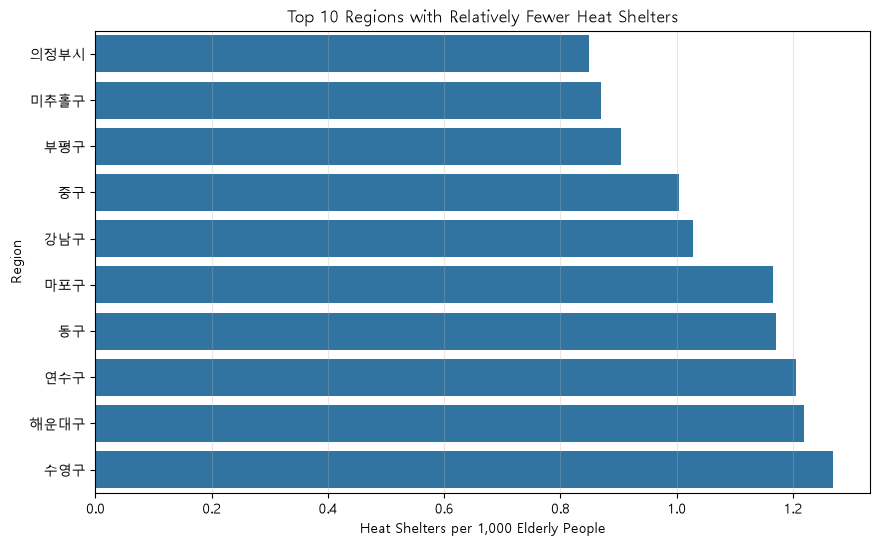

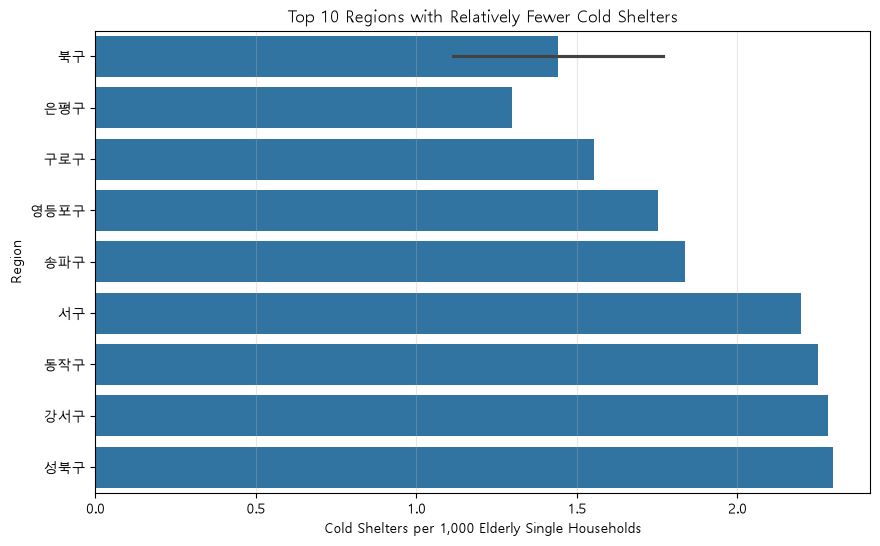

In [16]:
import matplotlib.pyplot as plt

# font를 나눔고딕으로 세팅 'NanumGothic'  - windows
plt.rcParams['font.family'] =  'Malgun Gothic'

# 무더위쉼터 TOP 10 시각화
plt.figure(figsize=(10, 6))

sns.barplot(
    data=heat_top10,
    x='고령인구_1000명당_무더위쉼터',
    y='시군구'
)

plt.title('Top 10 Regions with Relatively Fewer Heat Shelters')
plt.xlabel('Heat Shelters per 1,000 Elderly People')
plt.ylabel('Region')
plt.grid(axis='x', alpha=0.3)

plt.show()


# 한파쉼터 TOP 10 시각화
plt.figure(figsize=(10, 6))

sns.barplot(
    data=cold_top10,
    x='노인1인가구_1000가구당_한파쉼터',
    y='시군구'
)

plt.title('Top 10 Regions with Relatively Fewer Cold Shelters')
plt.xlabel('Cold Shelters per 1,000 Elderly Single Households')
plt.ylabel('Region')
plt.grid(axis='x', alpha=0.3)

plt.show()

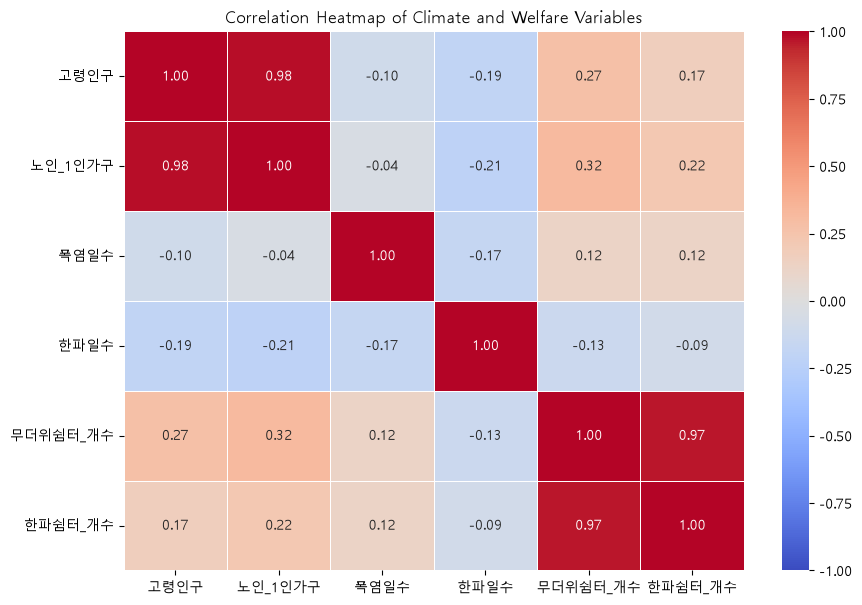

In [17]:
# 상관관계 분석 대상 변수
correlation_columns = [
    '고령인구',
    '노인_1인가구',
    '폭염일수',
    '한파일수',
    '무더위쉼터_개수',
    '한파쉼터_개수'
]

# 상관관계 계산
corr = df_2025[correlation_columns].corr()

# 상관관계 히트맵
plt.figure(figsize=(10, 7))

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5,
    vmin=-1,
    vmax=1
)

plt.title('Correlation Heatmap of Climate and Welfare Variables')
plt.show()

In [18]:
# 폭염일수 상위 10개 지역
heat_risk_top10 = df_2025.sort_values(
    '폭염일수',
    ascending=False
).head(10)

print("===== 폭염일수 TOP 10 =====")

print(
    heat_risk_top10[
        ['시도', '시군구', '폭염일수', '고령인구',
         '노인_1인가구', '무더위쉼터_개수']
    ].to_string(index=False)
)


# 한파일수 상위 10개 지역
cold_risk_top10 = df_2025.sort_values(
    '한파일수',
    ascending=False
).head(10)

print("\n===== 한파일수 TOP 10 =====")

print(
    cold_risk_top10[
        ['시도', '시군구', '한파일수', '고령인구',
         '노인_1인가구', '한파쉼터_개수']
    ].to_string(index=False)
)

===== 폭염일수 TOP 10 =====
   시도 시군구  폭염일수  고령인구  노인_1인가구  무더위쉼터_개수
 경상북도 성주군    62 16762     3997       266
 경상북도 칠곡군    62 22933     5649       264
 경상북도 구미시    62 57260    13208       279
 경상남도 창녕군    60 22059     6266       407
 경상북도 청도군    60 18650     4877       330
 경상남도 밀양시    60 36256    10067       334
 경상북도 경주시    57 70432    18006       247
 경상북도 의성군    56 23570     6769       534
대구광역시 군위군    56 10992     2471       217
 경상남도 양산시    54 68929    16905       273

===== 한파일수 TOP 10 =====
     시도 시군구  한파일수  고령인구  노인_1인가구  한파쉼터_개수
강원특별자치도 철원군    31 11931     2894      147
    경기도 파주시    26 90515    17404      416
강원특별자치도 화천군    24  6658     1767       94
강원특별자치도 정선군    21 12562     3483       49
강원특별자치도 평창군    21 14871     4000       47
   충청북도 제천시    21 37074     9517      103
강원특별자치도 양구군    18  5726     1363      119
강원특별자치도 인제군    18  8381     2083       42
강원특별자치도 태백시    18 12135     3727       32
강원특별자치도 삼척시    18 19458     5468       63


# 10. EDA 종합 결과 및 시사점

## 10-1. EDA 분석 결과 요약

| 번호 | 분석 항목 | 분석 결과 |
|---|---|---|
| 1 | 데이터 기본 정보 | 총 1,145행, 23개 컬럼, 229개 시군구, 2021~2025년 데이터 |
| 2 | 데이터 품질 확인 | 결측치 0개, 완전 중복 데이터 0개, 지역·연도별 중복 데이터 없음 |
| 3 | 고령인구 변화 | 2021년부터 2025년까지 지속적인 증가 추세 |
| 4 | 노인 1인가구 변화 | 2021년부터 2025년까지 지속적인 증가 추세 |
| 5 | 폭염일수 변화 | 2024년 급증하였으며, 2025년에도 높은 수준 유지 |
| 6 | 한파일수 변화 | 2021년부터 2024년까지 감소한 후 2025년 증가 |
| 7 | 쉼터 현황 | 지역별 무더위쉼터 평균 약 273개, 한파쉼터 평균 약 240개 |
| 8 | 인구 대비 쉼터 분석 | 일부 지역에서 인구 규모 대비 쉼터 개수가 상대적으로 적은 것으로 확인 |
| 9 | 상관관계 분석 | 고령인구와 노인 1인가구의 상관계수 0.98, 무더위쉼터와 한파쉼터의 상관계수 0.97 |
| 10 | 기후 위험 지역 분석 | 폭염일수는 경북·경남 지역, 한파일수는 강원 지역에서 높은 수준으로 나타남 |

## 10-2. 주요 분석 결과 및 시사점

### ① 고령인구 및 노인 1인가구 증가

2021년부터 2025년까지 고령인구와 노인 1인가구가 지속적으로 증가하는 추세를 확인하였다. 이는 기후재난에 취약할 수 있는 고령층에 대한 지속적인 복지 지원의 필요성을 보여준다.

### ② 지역별 기후 위험 차이

폭염일수는 경상북도와 경상남도 지역에서 높게 나타났으며, 한파일수는 강원특별자치도 지역에서 높게 나타났다. 이를 통해 기후 위험은 지역별로 차이가 있으며, 지역 특성을 반영한 맞춤형 분석이 필요하다는 점을 확인하였다.

### ③ 인구 규모와 쉼터 현황의 관계

고령인구 및 노인 1인가구와 쉼터 개수 사이에는 상대적으로 낮은 상관관계가 나타났다. 따라서 단순한 쉼터 개수만으로 복지 지원의 적정성을 판단하기 어렵다는 점을 확인하였다. 인구 규모와 쉼터 현황을 함께 고려한 분석이 필요하다.

### ④ 지역별 복지 지원 우선순위 분석의 필요성

지역별 기후 위험, 고령인구, 노인 1인가구, 쉼터 현황을 종합적으로 고려하여 복지 취약지역을 분석할 필요가 있다. 이를 바탕으로 지역별 취약성을 파악하고, 복지 지원 우선순위를 도출하고자 한다.

## 10-3. 데이터 분석 시 주의사항

- 무더위쉼터와 한파쉼터 개수는 2021~2025년 모든 지역에서 동일하게 나타났다. 따라서 연도별 변화 데이터가 아닌 지역별 현황 데이터로 취급하였다.
- 인구 대비 쉼터 비율은 인구 규모에 따른 쉼터 개수의 상대적 수준을 나타내며, 실제 쉼터 수용 인원이나 접근성을 의미하지는 않는다.
- 기후 데이터에는 관측일수 부족 여부를 나타내는 변수가 포함되어 있으므로, 폭염일수와 한파일수를 해석할 때 관측 데이터의 품질을 함께 고려해야 한다.
- 상관관계 분석은 변수 간 관련성을 파악하기 위한 것이며, 변수 간 인과관계를 의미하지 않는다.

## 10-4. 다음 단계 분석 방향

EDA 결과를 바탕으로 다음 단계에서는 K-Means 군집분석을 진행하고자 한다.

고령인구, 노인 1인가구, 폭염일수, 한파일수, 무더위쉼터 및 한파쉼터 현황 등을 활용하여 지역별 특성을 분석하고, 유사한 특성을 가진 지역끼리 군집화할 계획이다.

이후 군집분석 결과와 지역별 취약성 지표를 종합하여 기후재난 복지 지원 우선순위를 도출하고자 한다.